# Ground state of a 2D quantum dot

We look for the ground state of $N = 6$ spin-polarized electrons in a two-dimensional isotropic harmonic trap,

$$
H = \sum_{i=1}^{N} \left( -\frac{1}{2} \nabla_i^2 + \frac{\omega^2}{2} r_i^2 \right) + \sum_{i<j} \frac{1}{|\mathbf{r}_i - \mathbf{r}_j|}, \qquad \omega = 1,
$$

in units $\hbar = m = e^2 / 4 \pi \varepsilon = 1$.

The variational wave function is a single Slater determinant of harmonic-oscillator orbitals, with a Jastrow factor and a backflow that are both expanded in harmonic-oscillator orbitals, plus an electron-electron cusp. All parameters are complex and the network is holomorphic in them. We compare the variational energy with full configuration interaction (FCI) in a truncated harmonic-oscillator basis.

In [1]:
from itertools import combinations
from math import comb, factorial, pi

import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
import flax.linen as nn
import optax
from scipy.special import jv
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh

import os
os.environ["JVMC_BATCH_LOOP"] = "compiled"
import jVMC_exp
import jVMC_exp.operator.continuous as op

Running in single-node mode (JVMC_USE_DISTRIBUTED not set)


/Users/som30090/code/Custom_jVMC/jVMC_exp/solver/util.py:9: JaxMgWarning: Unsupported platform darwin, only Linux is supported. Non-Linux only works for docs.
  import jaxmg
/Users/som30090/code/Custom_jVMC/jVMC_exp/solver/util.py:9: JaxMgWarning: No GPUs found, only use this mode for testing or generating documentation.
  import jaxmg


## System

In [2]:
N = 6
n_dim = 2
omega = 1.0

# Open boundaries: the extent only sets where the walkers start and the initial step of the random walk
geometry = jVMC_exp.geometry.HyperRectangle(N, n_dim, PBC=False, extent=(6., 6.))

hamiltonian = (
    op.TotalKineticOperator(geometry)
    + op.PotentialOperator(geometry, lambda x: 0.5 * omega ** 2 * jnp.sum(x ** 2))
    + op.CoulombInteraction(geometry)
)

## Harmonic-oscillator orbitals

The single-particle eigenstates of the trap are

$$
\varphi_{nm}(r, \theta) = c_{nm} \, (\sqrt{\omega} r)^{|m|} \, L_n^{|m|}(\omega r^2) \, e^{-\omega r^2 / 2} \, e^{i m \theta}, \qquad \varepsilon_{nm} = \omega \, (2n + |m| + 1),
$$

with $L_n^{|m|}$ the generalized Laguerre polynomials. The shell $s = 2n + |m|$ holds $s + 1$ orbitals, so keeping the first $E_c$ shells gives $E_c (E_c + 1) / 2$ orbitals. For $N = 6$ the three lowest shells are exactly filled ($1 + 2 + 3$), so the non-interacting ground state is a closed shell with energy $14\,\omega$ and total angular momentum $M = \sum_i m_i = 0$.

The same class is used by the network (`__call__`, in JAX) and by the FCI below (`radial`, in NumPy).

In [3]:
def powers(x, n):
    # [1, x, ..., x^n] on the last axis
    p = [jnp.ones_like(x)]
    for _ in range(n):
        p.append(p[-1] * x)
    return jnp.stack(p, axis=-1)

class HOOrbitals:
    # 2D harmonic-oscillator orbitals of the first E_c shells, sorted by energy
    def __init__(self, E_c, omega=1.0):
        # shell s = 2n + |m| holds the orbitals m = -s, -s + 2, ..., s
        self.n, self.m = np.array(
            [
                ((s - abs(m)) // 2, m) 
                for s in range(E_c) 
                for m in range(-s, s + 1, 2)
            ]
        ).T
        self.omega = omega
        self.energies = omega * (2 * self.n + np.abs(self.m) + 1)
        self.num_orbitals = len(self.n)
        self._abs_m = np.abs(self.m)

        # c_nm times the coefficients of L_n^a(t) = sum_k (-1)^k binom(n + a, n - k) t^k / k!
        norm = np.sqrt(
            [
                omega * factorial(n) / (pi * factorial(n + a)) 
                for n, a in zip(self.n, self._abs_m)
            ]
        )
        self._coeffs = norm[:, None] * np.array([
            [
                (-1) ** k * comb(n + a, n - k) / factorial(k) if k <= n else 0. 
                for k in range(self.n.max() + 1)
            ] for n, a in zip(self.n, self._abs_m)
        ])

    def __call__(self, x):
        # x: positions with shape (n_particles, 2) -> phi_a(r_i) with shape (n_particles, num_orbitals)
        t = self.omega * jnp.sum(x ** 2, axis=-1)
        # (sqrt(w) r)^|m| e^{i m theta} = z^m or conj(z)^|m|
        z = jnp.sqrt(self.omega) * (x[:, 0] + 1j * x[:, 1])  
        a_max = self._abs_m.max()
        z_m = jnp.where(
            self.m >= 0, 
            powers(z, a_max)[:, self._abs_m], 
            powers(z.conj(), a_max)[:, self._abs_m]
        )

        return z_m * (powers(t, self.n.max()) @ self._coeffs.T) * jnp.exp(-t / 2)[:, None]

    def radial(self, r):
        # real radial parts R_a(r) = phi_a(r) e^{-i m_a theta}, with shape (num_orbitals, len(r))
        t = self.omega * r ** 2
        return np.sqrt(t) ** self._abs_m[:, None] * (self._coeffs @ t ** np.arange(self.n.max() + 1)[:, None]) * np.exp(-t / 2)

## FCI reference

In second quantization on the orbitals of the first $E_c$ shells,

$$
H = \sum_a \varepsilon_a c_a^\dagger c_a + \frac{1}{2} \sum_{ijkl} V_{ijkl} \, c_i^\dagger c_j^\dagger c_l c_k, \qquad
V_{ijkl} = \int d\mathbf{x} \, d\mathbf{y} \, \frac{\varphi_i^*(\mathbf{x}) \varphi_j^*(\mathbf{y}) \varphi_k(\mathbf{x}) \varphi_l(\mathbf{y})}{|\mathbf{x} - \mathbf{y}|}.
$$

Since the 2D Fourier transform of $1/r$ is $2\pi/q$, the Coulomb integrals reduce to one-dimensional integrals of Hankel transforms,

$$
V_{ijkl} = 4 \pi^2 \, \delta_{m_i + m_j, \, m_k + m_l} \int_0^\infty dq \, G_{ik}(q) \, G_{jl}(q), \qquad
G_{ik}(q) = \int_0^\infty dr \, r \, R_i(r) R_k(r) \, J_{|m_k - m_i|}(q r),
$$

which we evaluate with Gauss-Legendre quadrature. $H$ conserves the total angular momentum $M$, so we diagonalize only the $M = 0$ block, which holds the closed-shell ground state. FCI is variational in the basis size: its energy decreases as $E_c$ grows.

In [4]:
def coulomb_integrals(orbs, n_quad=300, r_max=12., q_max=25.):
    x, w = np.polynomial.legendre.leggauss(n_quad)
    r, w_r = (x + 1) * r_max / 2, w * r_max / 2
    q, w_q = (x + 1) * q_max / 2, w * q_max / 2

    R = orbs.radial(r)
    rho = R[:, None, :] * R[None, :, :] * r * w_r  # (i, k, r)
    dm = np.abs(orbs.m[:, None] - orbs.m[None, :])
    G = np.zeros(dm.shape + (n_quad,))
    for mu in np.unique(dm):
        G[dm == mu] = rho[dm == mu] @ jv(mu, np.outer(q, r)).T

    V = 4 * pi ** 2 * np.einsum("ikq, jlq, q -> ijkl", G, G, w_q, optimize=True)
    m = orbs.m
    V[m[:, None, None, None] + m[None, :, None, None] != m[None, None, :, None] + m[None, None, None, :]] = 0.

    return V

def fci_ground_state_energy(orbs, n_particles, V, M=0):
    # Slater determinants with total angular momentum M as bitmasks: |D> = c_a^+ c_b^+ ... |0> with a < b < ...
    n_orb = orbs.num_orbitals
    dets = np.sort(
        [
            sum(1 << a for a in occ) 
            for occ in combinations(range(n_orb), n_particles) if orbs.m[list(occ)].sum() == M
        ]
    )

    def apply(d, a, create):
        # c_a^+ (create) or c_a on the determinants d: new determinants, fermionic sign, mask of non-vanishing results
        valid = ((d >> a) & 1) == (0 if create else 1)
        sign = 1 - 2 * (np.bitwise_count(d & ((1 << a) - 1)).astype(int) % 2)
        return d ^ (1 << a), sign, valid

    occupation = (dets[:, None] >> np.arange(n_orb)) & 1
    rows, cols, vals = [np.arange(len(dets))], [np.arange(len(dets))], [occupation @ orbs.energies]

    # Interaction as sum_{i<j, k<l} (V_ijkl - V_ijlk) c_i^+ c_j^+ c_l c_k
    pairs = np.array(list(combinations(range(n_orb), 2)))
    W = (V - V.transpose(0, 1, 3, 2))[pairs[:, 0], pairs[:, 1]][:, pairs[:, 0], pairs[:, 1]]
    for (k, l), W_kl in zip(pairs, W.T):
        d, s_k, ok_k = apply(dets, k, False)
        d, s_l, ok_l = apply(d, l, False)
        idx = np.nonzero(ok_k & ok_l)[0]
        d, s = d[idx], (s_k * s_l)[idx]
        nonzero = np.abs(W_kl) > 1e-12
        for (i, j), w in zip(pairs[nonzero], W_kl[nonzero]):
            d_j, s_j, ok_j = apply(d, j, True)
            d_i, s_i, ok_i = apply(d_j, i, True)
            ok = ok_j & ok_i
            rows.append(np.searchsorted(dets, d_i[ok]))
            cols.append(idx[ok])
            vals.append(w * (s * s_j * s_i)[ok])

    H = csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(len(dets),) * 2)
    return eigsh(H, k=1, which="SA")[0][0]

In [5]:
E_fci = {}
for E_c in [5, 6, 7, 8, 9]:
    orbs = HOOrbitals(E_c, omega)
    E_fci[E_c] = fci_ground_state_energy(orbs, N, coulomb_integrals(orbs))
    print(f"E_c = {E_c} ({orbs.num_orbitals} orbitals): E_FCI = {E_fci[E_c]:.6f}")

E_c = 5 (15 orbitals): E_FCI = 22.010974
E_c = 6 (21 orbitals): E_FCI = 22.002221
E_c = 7 (28 orbitals): E_FCI = 21.996814
E_c = 8 (36 orbitals): E_FCI = 21.993825
E_c = 9 (45 orbitals): E_FCI = 21.991922


## Ansatz

$$
\log \psi(x) = \log \det \big[ (\Phi C) \odot (1 + B) \big] + J + J_\mathrm{cusp}
$$

- **Determinant**: $\Phi_{ia} = \varphi_a(\mathbf{r}_i)$ on the orbitals of the first `E_c_det` shells. The complex matrix $C$ mixes them into $N$ orbitals. It starts at the identity, so the determinant starts as the non-interacting ground state.
- **Backflow** (multiplicative): $B_{ik} = \sum_{ab} \varphi_a(\mathbf{r}_i) A^{(k)}_{ab} \bar\varphi_b(i)$, with $\bar\varphi(i) = \frac{1}{N-1} \sum_{j \neq i} \varphi(\mathbf{r}_j)$. Row $i$ depends on $\mathbf{r}_i$ and symmetrically on the other particles, so the determinant stays antisymmetric.
- **Jastrow**: $J = \sum_{i<j} \varphi(\mathbf{r}_i)^T A \, \varphi(\mathbf{r}_j)$ with $A$ symmetric.
- **Cusp**: $J_\mathrm{cusp} = -\sum_{i<j} \frac{1}{3} \frac{p^2}{p + r_{ij}}$ has slope $1/3$ at $r_{ij} = 0$, which is the Kato cusp condition for same-spin electrons in 2D.

In [6]:
complex_normal = lambda std: nn.initializers.normal(stddev=std, dtype=jnp.complex128)

class OrbitalJastrow(nn.Module):
    orbitals: HOOrbitals
    std_init: float = 1e-1

    @nn.compact
    def __call__(self, x):
        phi = self.orbitals(x)
        A = self.param(
            "A", 
            complex_normal(self.std_init), 
            (self.orbitals.num_orbitals,) * 2, 
            jnp.complex128
        )

        return (phi @ (A + A.T) / 2 @ phi.T)[jnp.triu_indices(x.shape[0], 1)].sum()

class ElectronCusp(nn.Module):
    cusp: float = 1 / 3  # 1 / (d + 1) for same-spin electrons in d dimensions

    @nn.compact
    def __call__(self, x):
        p = self.param("p", nn.initializers.ones, (), jnp.complex128)
        r = jnp.linalg.norm(
            (x[:, None, :] - x[None, :, :])[jnp.triu_indices(x.shape[0], 1)], 
            axis=-1
        )

        return -jnp.sum(self.cusp * p ** 2 / (p + r))

class OrbitalBackflow(nn.Module):
    orbitals: HOOrbitals
    std_init: float = 1e-2

    @nn.compact
    def __call__(self, x):
        n_particles = x.shape[0]
        phi = self.orbitals(x)
        phi_others = (phi.sum(axis=0) - phi) / (n_particles - 1)
        A = self.param(
            "A", 
            complex_normal(self.std_init), 
            (n_particles,) + (self.orbitals.num_orbitals,) * 2, 
            jnp.complex128
        )

        return jnp.einsum("ia,kab,ib->ik", phi, A, phi_others)

class SlaterJastrowBackflow(nn.Module):
    n_particles: int
    orbitals: HOOrbitals
    jastrow: nn.Module
    cusp: nn.Module
    backflow: nn.Module
    std_init: float = 1e-3

    @nn.compact
    def __call__(self, x):
        x = x.reshape(self.n_particles, 2)
        C = self.param(
            "C",
            lambda key, shape, dtype: jnp.eye(*shape, dtype=dtype) + complex_normal(self.std_init)(key, shape, dtype),
            (self.orbitals.num_orbitals, self.n_particles),
            jnp.complex128
        )

        sign, log_abs_det = jnp.linalg.slogdet((self.orbitals(x) @ C) * (1 + self.backflow(x)))

        return log_abs_det + jnp.log(sign) + self.jastrow(x) + self.cusp(x)

In [7]:
E_c_det, E_c_jastrow, E_c_bf = 6, 4, 4
n_samples = 2**11

net = SlaterJastrowBackflow(
    n_particles=N,
    orbitals=HOOrbitals(E_c_det, omega),
    jastrow=OrbitalJastrow(HOOrbitals(E_c_jastrow, omega)),
    cusp=ElectronCusp(),
    backflow=OrbitalBackflow(HOOrbitals(E_c_bf, omega)),
)
psi = jVMC_exp.vqs.NQS(net, sampleShape=n_dim * N, batchSize=n_samples, seed=123)
proposer = jVMC_exp.propose.RWM(geometry)
sampler = jVMC_exp.sampler.MCSamplerCont(
    psi, proposer, key=123, numChains=n_samples // 4, numSamples=n_samples,
    sweepSteps=2 * N, thermalizationSweeps=5
)

print("Number of parameters:", psi.numParameters)
print("Holomorphic:", psi.holomorphic)

Number of parameters: 827
Holomorphic: True


## Optimization

Stochastic reconfiguration with a piecewise-constant learning rate.

In [8]:
n_steps = 100
lr = optax.piecewise_constant_schedule(
    5e-2, {int(0.4 * n_steps): 0.3, int(0.7 * n_steps): 0.3, int(0.9 * n_steps): 0.3}
)
stepper = jVMC_exp.stepper.Euler(lr)
loss_function = jVMC_exp.objective_function.Observable(hamiltonian)
solver = jVMC_exp.solver.Pinv()
opt = jVMC_exp.optimizer.SR(sampler, psi, diagonalShift=1e-4, solver=solver)

out = opt.ground_state_search(n_steps, loss_function, stepper)

/Users/som30090/code/Custom_jVMC/jVMC_exp/optimizer/base.py:305: UserWarning: Naming convention changed: 'diag_shift' now adds a constant term to the diagonal, while 'diag_scale' multiplies the diagonal entries. This is the opposite of the previous convention.
  warnings.warn(
100%|██████████| 100/100 [01:16<00:00,  1.31it/s, E=2.1988e+01-1.2458e-04j ± 1.0262e-03 (Var = 2.1567e-03)]

Recorded timings:
    - sampling: 12.465014s
    - compute objective function and gradient: 32.119293s
    - solve: 30.883280s


## Comparison with FCI

Both energies are upper bounds to the exact ground-state energy. The FCI energy is not yet converged at $E_c = 7$ (each extra shell still lowers it by a few $10^{-3}$), so the VMC energy can end up below it.

In [9]:
E = sampler(hamiltonian, num_samples=2**14)
E_vmc, E_err = E.mean.real.item(), E.error_of_mean.real.item()
E_ref = E_fci[max(E_fci)]

print(f"E_VMC = {E_vmc:.4f} +- {E_err:.4f}")
print(f"E_FCI = {E_ref:.4f}  (E_c = {max(E_fci)})")
print(f"relative difference: {(E_vmc - E_ref) / E_ref:.1e}")

E_VMC = 21.9870 +- 0.0004
E_FCI = 21.9919  (E_c = 9)
relative difference: -2.3e-04


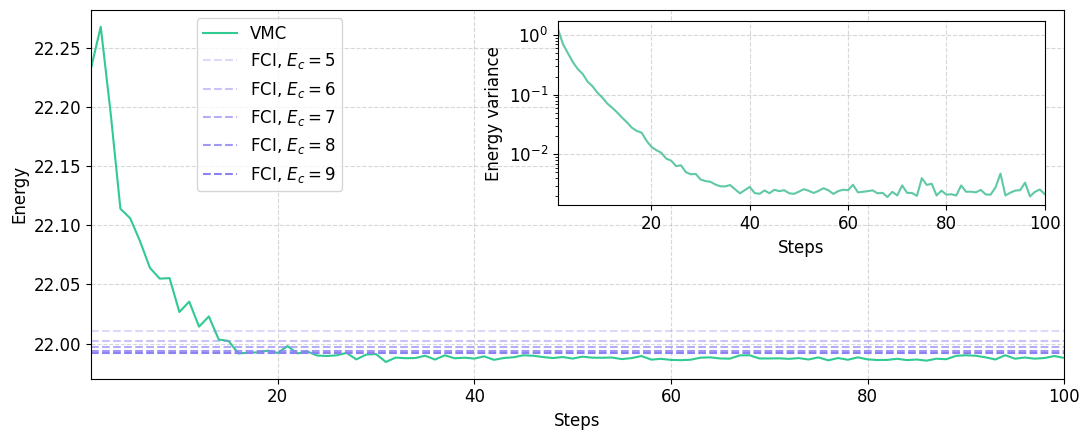

In [11]:
fontsize = 12
steps = np.array(out["times"]) + 1
energy = np.array(out["energy"]["mean"])
variance = np.array(out["energy"]["variance"])

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(steps, energy, label="VMC", color="#30ca92")
for (E_c, E), alpha in zip(sorted(E_fci.items()), np.linspace(0.3, 1, len(E_fci))):
    ax.axhline(E, color="#8d82f4", ls="--", alpha=alpha, label=f"FCI, $E_c = {E_c}$")
ax.set_xlabel("Steps", fontsize=fontsize)
ax.set_ylabel("Energy", fontsize=fontsize)
ax.set_xlim(1, n_steps)
ax.legend(loc="upper left", bbox_to_anchor=(0.1, 1), fontsize=fontsize)
ax.grid(ls="--", alpha=0.5)
ax.tick_params(labelsize=fontsize)

# Inset position as [x0, y0, width, height], in fractions of the main axes
inset = ax.inset_axes([0.48, 0.47, 0.5, 0.5])
inset.plot(steps, variance, color="#5fc9a3")
inset.set_yscale("log")
inset.set_xlabel("Steps", fontsize=fontsize)
inset.set_ylabel("Energy variance", fontsize=fontsize)
inset.tick_params(labelsize=fontsize)
inset.grid(ls="--", alpha=0.5)
inset.set_xlim(1, n_steps)

plt.tight_layout()

plt.savefig('quantum_dot_2d.pdf')
plt.show()